# TitleGuard: Online Title Similarity Verification
### SIH1782 · Third Internal Data Science Project

**Question:** Does a proposed publication title resemble an existing title closely enough to require review?

Open this notebook in Google Colab and select **Runtime → Run all**. When prompted, upload the accompanying **registry.csv** file. A CPU runtime is sufficient. The accompanying CSV contains an invented registry. The notebook includes an explainable retrieval model, a learned pair classifier, evaluation, and an interactive submission form. No API key or Google Drive access is required. Replace the registry with licensed real data before making real decisions.

**Scope:** This is a college prototype inspired by SIH1782, not an official government verification service. It does not grant title approval. The final decision belongs to a human reviewer. Scores are similarity evidence, not calibrated probabilities of legal acceptance.

**Learning outcomes:** data import/cleaning and visualization; descriptive statistics and inference; logistic regression, clustering and similarity; content-based recommendations and ranking evaluation; privacy, transparency and limitations. Collaborative filtering is unsuitable because we have no user interaction history.

## Two-file access guide
1. Download **registry.csv** from this GitHub repository to your computer.
2. Open **TitleGuard_SIH1782.ipynb** in Colab, then select **Runtime → Run all**.
3. In the dataset cell, click **Choose Files** and select **registry.csv**. Allow the remaining cells to finish.
4. Scroll to **6. Interactive online submission demo**, type a proposed title and click **Verify title**.

No Git commands, cloning, GPU, API keys or Drive mounting are needed. To keep your own editable copy, select **File → Save a copy in Drive**. Upload the CSV again after a runtime reset. Running cells in order preserves all analysis, training, evaluation, statistics, clustering and the interactive form.

**Dataset provenance:** 72 invented publication titles, not an official registry. Pair labels are rule-generated educational examples. The family-held-out evaluation measures this synthetic task only. Real submissions need authoritative data and independently annotated evaluation.


In [1]:
# Install only missing runtime requirements; no GPU or external model download.
import importlib.util, subprocess, sys
packages = {'numpy':'numpy>=1.26,<3', 'pandas':'pandas>=2.1,<3',
            'scipy':'scipy>=1.11,<2', 'sklearn':'scikit-learn>=1.4,<2',
            'matplotlib':'matplotlib>=3.8,<4', 'ipywidgets':'ipywidgets>=8.1,<9'}
missing = [spec for module, spec in packages.items() if importlib.util.find_spec(module) is None]
if missing: subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
import os
os.environ.setdefault('MPLCONFIGDIR', '/tmp/titleguard-matplotlib')
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
print('CPU runtime ready.')

CPU runtime ready.


## 1. Import, clean and inspect data
The accompanying CSV contains 72 synthetic titles and explicit provenance. We preserve raw input, check missing values, filter invalid rows, normalize Unicode and punctuation, remove duplicates, sort, group and rank. A real registry can be imported with `pd.read_csv(...)`, but evaluation needs independently annotated pairs and family groups too.

In [2]:
"""Explainable retrieval and pair classification for educational title screening."""
import re
import unicodedata
from difflib import SequenceMatcher
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics.pairwise import cosine_similarity


def normalize(text):
    if not isinstance(text, str):
        raise ValueError("Title must be text.")
    text = unicodedata.normalize("NFKC", text).casefold()
    text = " ".join(re.findall(r"[^\W_]+", text, flags=re.UNICODE))
    if not text:
        raise ValueError("Enter a title containing letters or numbers.")
    if len(text) > 500:
        raise ValueError("Title must contain at most 500 normalized characters.")
    return text


def features(a, b):
    """Symmetric pair features; no fitted vocabulary or registry labels required."""
    a, b = normalize(a), normalize(b)
    x, y = set(a.split()), set(b.split())
    grams = lambda s: set(s[i:i+3] for i in range(max(1, len(s)-2)))
    u, v = grams(a), grams(b)
    return [float(a == b), len(x & y)/len(x | y),
            SequenceMatcher(None, a, b, autojunk=False).ratio(),
            min(len(a), len(b))/max(len(a), len(b)), len(u & v)/len(u | v)]


class TitleVerifier:
    def __init__(self, registry):
        required = {"title_id", "title"}
        if not required.issubset(registry.columns):
            raise ValueError("Registry requires title_id and title columns.")
        if registry.empty or registry.title_id.isna().any() or registry.title_id.duplicated().any():
            raise ValueError("Registry needs nonempty, unique title IDs.")
        self.registry = registry.copy().reset_index(drop=True)
        self.normalized = self.registry.title.map(normalize)
        if self.normalized.duplicated().any():
            raise ValueError("Registry contains duplicate normalized titles; clean it first.")
        self.word = TfidfVectorizer(ngram_range=(1, 2), token_pattern=r"(?u)\b\w+\b")
        self.char = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5))
        self.w = self.word.fit_transform(self.normalized)
        self.c = self.char.fit_transform(self.normalized)
        self.model = None
        self.threshold = 0.5

    def fit_pairs(self, pairs):
        if not {0, 1}.issubset(set(pairs.label)):
            raise ValueError("Training needs both positive and negative pairs.")
        self.model = LogisticRegression(class_weight="balanced", random_state=42, max_iter=1000)
        self.model.fit([features(a, b) for a, b in zip(pairs["query"], pairs.candidate)], pairs.label)
        return self

    def pair_scores(self, pairs):
        if self.model is None:
            raise RuntimeError("Train the pair classifier first.")
        return self.model.predict_proba([features(a, b) for a, b in zip(pairs["query"], pairs.candidate)])[:, 1]

    def search(self, title, top_k=5):
        q = normalize(title)
        if not isinstance(top_k, int) or top_k < 1:
            raise ValueError("top_k must be a positive integer.")
        score = .4*cosine_similarity(self.word.transform([q]), self.w)[0] + .6*cosine_similarity(self.char.transform([q]), self.c)[0]
        ids = np.argsort(-score, kind="stable")[:top_k]
        # Always prioritize normalized exact matches, even for a registry with tied scores.
        exact_ids = np.flatnonzero(self.normalized.to_numpy() == q)
        ids = list(dict.fromkeys([*exact_ids, *ids]))[:top_k]
        out = self.registry.iloc[ids].copy()
        out["similarity"] = score[ids]
        out["exact_match"] = self.normalized.iloc[ids].to_numpy() == q
        if self.model is not None:
            out["pair_score"] = self.model.predict_proba([features(q, t) for t in out.title])[:, 1]
            out["decision"] = ["EXACT MATCH" if e else "REVIEW" if p >= self.threshold else "LOW SIMILARITY" for e, p in zip(out.exact_match, out.pair_score)]
        else:
            out["decision"] = np.where(out.exact_match, "EXACT MATCH", "REVIEW (UNTRAINED)")
        return out.reset_index(drop=True)

In [3]:
from pathlib import Path
from io import BytesIO

# Upload registry.csv only when it is not already present in this runtime.
# Colab deletes uploaded files when the runtime is reset; upload again then.
data_path = Path('registry.csv')
if not data_path.is_file():
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError('Place registry.csv beside this notebook before running it locally.') from exc
    print('Choose the registry.csv file downloaded from this repository.')
    uploaded = files.upload()
    if len(uploaded) != 1:
        raise ValueError('Upload exactly one CSV dataset, then rerun this cell.')
    filename, contents = next(iter(uploaded.items()))
    if not filename.lower().endswith('.csv'):
        raise ValueError('Select a CSV file, then rerun this cell.')
    raw = pd.read_csv(BytesIO(contents))
else:
    raw = pd.read_csv(data_path)

required_columns = {'title_id', 'title', 'category', 'family', 'source'}
if not required_columns.issubset(raw.columns):
    raise ValueError('Use the supplied registry.csv. Missing columns: ' + ', '.join(sorted(required_columns - set(raw.columns))))
print('Raw shape:', raw.shape)
display(raw.isna().sum().rename('missing'))
registry = raw.dropna(subset=['title_id', 'title', 'category', 'family']).copy()
registry['normalized'] = registry.title.map(normalize)
registry = registry.drop_duplicates('normalized').sort_values('title_id').reset_index(drop=True)
if registry.title_id.duplicated().any():
    raise ValueError('Each title_id must be unique.')
if registry.family.nunique() < 24:
    raise ValueError('The included family-held-out benchmark needs at least 24 families. Use the supplied registry.csv.')
registry['word_count'] = registry.normalized.str.split().str.len()
registry['length'] = registry.normalized.str.len()
display(registry.head())
display(registry.groupby('category').agg(titles=('title_id','count'), mean_length=('length','mean')).sort_values('mean_length', ascending=False))

Raw shape: (72, 5)


title_id    0
title       0
category    0
family      0
source      0
Name: missing, dtype: int64

,title_id,title,category,family,source,normalized,word_count,length
0,T001,The River Chronicle,Chronicle,river,synthetic educational example,the river chronicle,3,19
1,T002,The River Herald,Herald,river,synthetic educational example,the river herald,3,16
2,T003,The River Review,Review,river,synthetic educational example,the river review,3,16
3,T004,The City Chronicle,Chronicle,city,synthetic educational example,the city chronicle,3,18
4,T005,The City Herald,Herald,city,synthetic educational example,the city herald,3,15


,titles,mean_length
category,,
Chronicle,24,21.291667
Herald,24,18.291667
Review,24,18.291667


## 2. Exploratory data analysis and descriptive statistics

,length,word_count
count,72.000000,72.0
mean,19.291667,3.0
median,19.000000,3.0
var,5.448944,0.0
std,2.334297,0.0
min,15.000000,3.0
max,25.000000,3.0


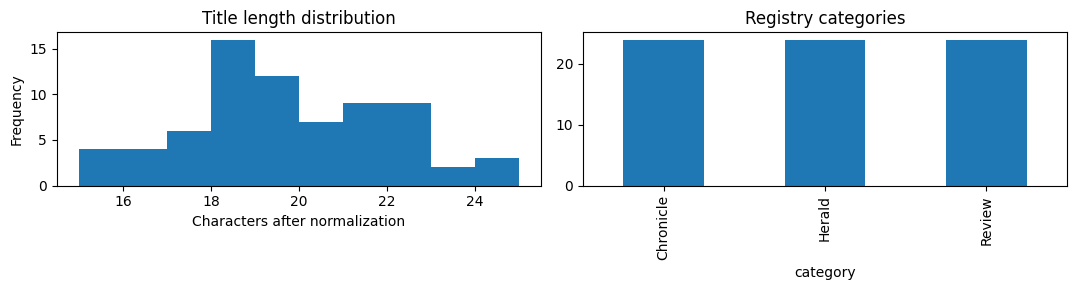

Length/word-count correlation:


,length,word_count
length,1.0,NaN
word_count,NaN,NaN


In [4]:
display(registry[['length','word_count']].agg(['count','mean','median','var','std','min','max']))
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
registry.length.plot.hist(bins=10, ax=ax[0], title='Title length distribution')
ax[0].set_xlabel('Characters after normalization')
registry.category.value_counts().plot.bar(ax=ax[1], title='Registry categories')
plt.tight_layout(); plt.show()
# Word count is constant in this template dataset: its correlation is undefined.
print('Length/word-count correlation:')
display(registry[['length','word_count']].corr())

## 3. Models and evaluation design
Retrieval combines word TF-IDF cosine similarity (40%) and character TF-IDF cosine similarity (60%). It returns the five closest registry titles, a content-based recommendation task. Character n-grams help with spelling variation; word n-grams retain context. We do not remove stop words because small wording differences may matter in names.

A logistic regression pair classifier uses normalized equality, token Jaccard, character sequence similarity, length ratio and trigram Jaccard. A high score triggers **REVIEW**, never automatic rejection. Exact normalized matches are explicitly flagged. LOW SIMILARITY is not legal approval.

Subject families are split with seed 42: 14 training, 5 validation and 5 test families. Negative candidates remain within their split. Threshold selection maximizes validation F1; test labels are untouched until reporting. Retrieval indexing uses the available registry, which is normal for search. The tiny templated benchmark is easier than real submissions and cannot establish production accuracy.

In [5]:
"""Reproducible family-held-out benchmark with validation-only threshold tuning."""
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix



def make_pairs(registry):
    families = registry.family.unique().copy()
    np.random.default_rng(42).shuffle(families)
    partitions = {"train":families[:14], "validation":families[14:19], "test":families[19:]}
    rows = []
    for split, groups in partitions.items():
        subset = registry[registry.family.isin(groups)].reset_index(drop=True)
        for i, row in subset.iterrows():
            title = row.title
            words = title.split()
            variants = [title.upper()+'!', ' '.join(words[1:]), ' '.join(words[::-1]), title[:-2]+title[-1]+title[-2]]
            for query in variants:
                rows.append([query, title, 1, row.family, split, row.title_id])
            # Hard negatives share the subject; easy negatives share the format.
            hard = subset[(subset.family == row.family) & (subset.title_id != row.title_id)].iloc[0]
            easy = subset[(subset.family != row.family) & (subset.category == row.category)].iloc[0]
            for negative in [hard, easy]:
                rows.append([title, negative.title, 0, row.family, split, negative.title_id])
    return pd.DataFrame(rows, columns=['query','candidate','label','family','split','candidate_id'])


def evaluate(verifier, pairs):
    train, val, test = [pairs[pairs.split == s].copy() for s in ['train','validation','test']]
    verifier.fit_pairs(train)
    scores = verifier.pair_scores(val)
    grid = np.linspace(.05, .95, 91)
    # Tie break toward a higher threshold. Validation data only.
    threshold = max(grid, key=lambda t: (f1_score(val.label, scores >= t, zero_division=0), t))
    verifier.threshold = float(threshold)
    pred = verifier.pair_scores(test) >= threshold
    metrics = {'threshold':float(threshold), 'test_pairs':len(test),
               'accuracy':accuracy_score(test.label,pred), 'precision':precision_score(test.label,pred,zero_division=0),
               'recall':recall_score(test.label,pred,zero_division=0), 'f1':f1_score(test.label,pred,zero_division=0),
               'confusion_matrix':confusion_matrix(test.label,pred,labels=[0,1]).tolist()}
    # Retrieval evaluated on positive test queries, against the full registry.
    positives = test[test.label == 1]
    ranks = []
    for row in positives.itertuples():
        found = verifier.search(row.query, top_k=5).title_id.tolist()
        ranks.append(found.index(row.candidate_id)+1 if row.candidate_id in found else 0)
    metrics['recall_at_5'] = float(np.mean(np.array(ranks)>0))
    metrics['mrr_at_5'] = float(np.mean([1/x if x else 0 for x in ranks]))
    test['pair_score'] = verifier.pair_scores(test)
    test['prediction'] = pred.astype(int)
    return metrics, test

label,different,same title
split,,
test,30,60
train,84,168
validation,30,60


threshold       0.750000
test_pairs     90.000000
accuracy        0.933333
precision       1.000000
recall          0.900000
f1              0.947368
recall_at_5     1.000000
mrr_at_5        1.000000
Name: Held-out result, dtype: float64

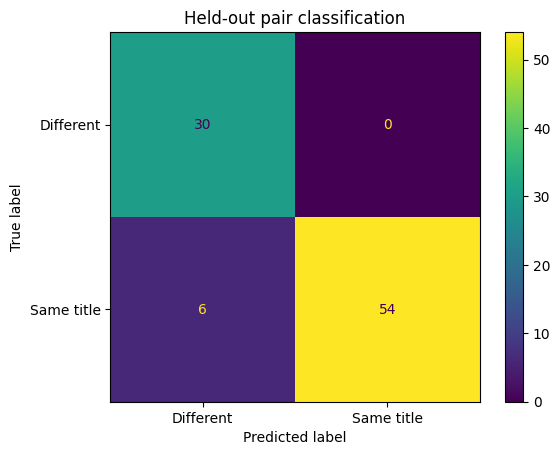

Held-out errors: 6


,query,candidate,label,family,split,candidate_id,pair_score,prediction
349,City Herald,The City Herald,1,city,test,T005,0.699265,0
350,Herald City The,The City Herald,1,city,test,T005,0.648887,0
351,The City Heradl,The City Herald,1,city,test,T005,0.713422,0
355,City Review,The City Review,1,city,test,T006,0.699265,0
356,Review City The,The City Review,1,city,test,T006,0.648887,0
357,The City Reviwe,The City Review,1,city,test,T006,0.713422,0


Token-Jaccard baseline test F1: 0.667
Measured results apply only to this synthetic benchmark.


In [6]:
pairs = make_pairs(registry)
display(pd.crosstab(pairs.split, pairs.label).rename(columns={0:'different',1:'same title'}))
verifier = TitleVerifier(registry)
metrics, test_predictions = evaluate(verifier, pairs)
display(pd.Series({k:v for k,v in metrics.items() if k != 'confusion_matrix'}, name='Held-out result'))
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay(np.array(metrics['confusion_matrix']), display_labels=['Different','Same title']).plot()
plt.title('Held-out pair classification'); plt.show()
errors = test_predictions[test_predictions.label != test_predictions.prediction]
print('Held-out errors:', len(errors))
display(errors if len(errors) else test_predictions.head())
# Compare with a fixed token-Jaccard baseline on the same test set.
from sklearn.metrics import f1_score
baseline = [features(a,b)[1] >= .8 for a,b in zip(test_predictions["query"],test_predictions.candidate)]
print('Token-Jaccard baseline test F1:', round(f1_score(test_predictions.label,baseline), 3))
print('Measured results apply only to this synthetic benchmark.')

## 4. Statistical inference
**H₀:** Mean token Jaccard similarity is equal for positive and negative title pairs.
**H₁:** The means differ. We compare one average per family and class on training data, reducing repeated-pair dependence. Welch's test is exploratory: only 14 synthetic training families exist; generated labels and templates violate assumptions needed for population claims. A small p-value is not evidence of production readiness.

The bootstrap below resamples whole held-out families for an approximate F1 interval. It reflects this benchmark only; five test families are too few for strong uncertainty claims.

In [7]:
from scipy.stats import ttest_ind
training = pairs[pairs.split == 'train'].copy()
training['jaccard'] = [features(a,b)[1] for a,b in zip(training["query"],training.candidate)]
family_means = training.groupby(['family','label']).jaccard.mean().unstack()
if np.isclose(family_means[1].var() + family_means[0].var(), 0):
    print('Welch test not estimable: family means have zero variance in this templated dataset.')
    print('No valid inferential p-value is reported. Use diverse real data for hypothesis testing.')
else:
    stat, p = ttest_ind(family_means[1], family_means[0], equal_var=False)
    print(f'Exploratory Welch t={stat:.3f}, p={p:.5g}; alpha=0.05')
    print('Reject H0 on this synthetic sample.' if p < .05 else 'Insufficient evidence to reject H0.')
rng = np.random.default_rng(42)
family_ids = test_predictions.family.unique()
boot = []
for _ in range(500):
    sample = pd.concat([test_predictions[test_predictions.family == g] for g in rng.choice(family_ids, len(family_ids), replace=True)])
    boot.append(f1_score(sample.label, sample.prediction, zero_division=0))
print('Approximate family-bootstrap F1 95% interval:', np.quantile(boot,[.025,.975]))
print('A zero-width interval on templated data does not mean zero real-world uncertainty.')

Welch test not estimable: family means have zero variance in this templated dataset.
No valid inferential p-value is reported. Use diverse real data for hypothesis testing.


Approximate family-bootstrap F1 95% interval: [0.82352941 1.        ]
A zero-width interval on templated data does not mean zero real-world uncertainty.


## 5. Unsupervised exploration
K-means groups registry titles by lexical content. Clusters are exploratory and do not determine title availability. Category labels are not used during clustering.

In [8]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
clusters = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(verifier.w)
print('Cosine silhouette:', round(silhouette_score(verifier.w, clusters, metric='cosine'), 3))
display(pd.crosstab(pd.Series(clusters, name='cluster'), registry.category))

Cosine silhouette: 0.053


category,Chronicle,Herald,Review
cluster,,,
0,22,22,0
1,1,1,1
2,1,1,23


## 6. Interactive online submission demo
Enter a proposed title and press **Verify title**. Try `THE RIVER CHRONICLE!`, `River Chroncile`, and a new unrelated title. The form runs inside the Colab browser session; it is not a deployed multi-user service. Submitted text is processed in memory and is not stored or sent to an external API. Review the five candidates, rather than relying on a single label.

In [9]:
import ipywidgets as widgets
try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass
entry = widgets.Text(value='River Chroncile', description='New title:', layout=widgets.Layout(width='80%'))
button = widgets.Button(description='Verify title', button_style='primary')
output_area = widgets.Output()
def verify_clicked(_):
    with output_area:
        clear_output(wait=True)
        try:
            matches = verifier.search(entry.value)
            decision = 'EXACT MATCH FOUND' if matches.exact_match.any() else 'HUMAN REVIEW RECOMMENDED' if (matches.decision == 'REVIEW').any() else 'NO STRONG MATCH FOUND — NOT AN APPROVAL'
            print(decision)
            display(matches[['title_id','title','similarity','pair_score','decision']].round(3))
            print('Similarity and pair scores are not calibrated approval probabilities.')
        except ValueError as exc:
            print(str(exc))
button.on_click(verify_clicked)
display(widgets.VBox([entry, button, output_area]))
verify_clicked(None)

## 7. Ethics, limitations and viva notes
- Only invented titles are included; no personal data or scraped registry is used. Do not upload confidential submissions to shared notebooks.
- English lexical similarity can miss transliteration, phonetic equivalence and semantic paraphrases. Common-word overlap can also create false positives. Audit by language, title length and subject before deployment.
- False positives send distinct titles for unnecessary review; false negatives can miss conflicts. Human review is required and thresholds need real operational validation.
- Explain a flag by showing matched titles, token overlap and character similarity. Logistic regression weights describe this synthetic training distribution; they are not a legal explanation.
- The system does not implement regulatory rules, database persistence, authentication or an official approval workflow. These are future deployment requirements.

**Viva prompts:** Why character TF-IDF? Why split by family? Why tune only on validation? How do precision and recall differ? Why does perfect synthetic accuracy not imply real accuracy? Why is content-based retrieval appropriate here? What data would be needed for collaborative filtering?

**Before submission:** add your name, register number and department; run every cell; retain actual outputs; describe the dataset honestly; follow your college's rules on acknowledging tools and assistance. Read and understand the code before presenting it.